In [8]:
# !mamba install -y -c conda-forge py-xgboost

In [9]:
import os
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sqlalchemy import create_engine

import ml_utils

plt.style.use("ggplot")

# Basic ML using scikit-learn

"Classic" ML approaches using scikit-learn.

**To do:**

**Near future:**
- Bit more fine-tuning of xgboost hyperparameters. How does the hyperparam optimum change across feature sets? Is it fairly stable?
- Also try with log(TOC) as y_var. CoPilot reckons might get decent performance improvement
- Spatial vs temporal performance. Ideas:
	* Remove site means and look at anomalies. Then calculate r2_score(obs_anom, pred_anom) on anomalies. i.e. can the model reproduce fluctuations around the site's typical TOC? Getting closer to temporal prediction skill.
	* Calcualte per-site R2. E.g. overall R2 might be 0.5, but if median site R2 is 0.05, then spatial variation dominates.
	* gold-standard test for temporal prediction: instead of groupKFold(site), train on early years and test on later years within the site. i.e. "Can I predict future TOC dynamics at a known site?" What year to use as split? Should it be balanced or not?
- Look at residuals grouped by various things, e.g.:
  * contractor
  * activity
  * vassdragsområde
  * season
  * catchment area
  * ...?
  Based on results, may be sensible to remove e.g. certain activities/contractors
- Play around with different feature sets. How robust is the model to choices here? What features should we always have in? What can we always drop?
- Get SHAP working
- At end: refit model to all data and save, ready for prediction elsewhere
- Understanding performance in the test set... Where it is good, is it just because there's another monitoring point just nearby? (How to establish? Could have some kind of % catchment overlap score?). Characteristics of sites with poor performance?

**Longer-term:**
- Harsher test: cross validation by vasssdragsområde, or in some other way exclude nearby sites from the training site from being in the validation set. i.e. no possibility for nearby sites to help improve predictions. Though vassdragsområde 002 (Glomma) has by far the most sampling points, so just by vassom probably not great.
- To predict soil TOC loss, might want a different model, excluding more human-impacted catchments?
- Continue adding to / improving the training dataset:
  * Where available, replace HBV-simulated runoff with (area-scaled) observed runoff (new feature)
  * MODIS-derived phenology features (snow, vegetattion)
  * Geology (e.g. acid sensitivity, plus setup for Ca), liming activities
  * Something about flow regulation/damming/hydro
  * Upstream mean water transit time estimate?

# Basic input

In [10]:
y_var = 'toc_mg_l'

# Minimum number of samples per site (used as criteria for site inclusion in the training data).
min_samps = 10  # Currently the only option is 10

# Column with site identifier in the training data
id_col = "site_code"

# Which feature set to use?
# Options: "full" (all but metadata cols), otherwie must be a named column present in sheet "toc_training-data-specification.csv"
feature_set = "v4_full-minus-time-place"

# Folder to store exploratory figures in
fig_folder = r"../../../output/ml_training"

# Read and filter training data matrix

The training data is compiled together and saved in a parquet file. In addition, there is an accompanying csv ("toc_training-data-specification.csv") which contains metadata for all the columns present in the training data. This csv can be used, for example, to make lists of metadata columns that should always be excluded from fitting. It is also a way of keeping track of experiments where we fit using different slices of the features.

In [11]:
# ---------- Directories/filepaths ----------
data_dir = r"/home/jovyan/shared/common/norsink/vm_catchments_data/training_data"
fname = f"training-data_TOC_full_min-samps-{min_samps}.parquet"
fpath = os.path.join(data_dir, fname)

# -------------
# Read data matrix
df = pd.read_parquet(fpath)

df["date"] = pd.to_datetime(df["date"])

print(len(df), "water samples from", len(df[id_col].unique()), "sites.")
df.head()

142577 water samples from 2552 sites.


,site_code,date,contractor,ActivityName,toc_mg_l,lon,lat,area_km2,vassomnr,slope_deg_mean,...,gts_runoff_daily_ecdf,gts_runoff_7d_sum,gts_runoff_30d_sum,gts_runoff_90d_sum,gts_precip_7d_sum,gts_precip_30d_sum,gts_precip_90d_sum,gts_temp_7d_mean,gts_temp_30d_mean,gts_temp_90d_mean
0,001-119928,2011-09-15,Eurofins (location unspecified),Tiltaksorientert overvåking,10.61,11.653745,59.47652,1008.505005,1,5.542838,...,0.968635,30.6543,68.8774,112.5280,57.5795,204.6595,454.8335,11.902286,13.116717,14.446294
1,001-119928,2012-10-09,Eurofins (location unspecified),Tiltaksorientert overvåking,9.96,11.653745,59.47652,1008.505005,1,5.542838,...,0.762379,8.7834,26.4669,62.0079,30.0655,130.1295,304.2480,6.048000,7.977317,11.737578
2,001-119928,2013-08-27,Eurofins (location unspecified),Tiltaksorientert overvåking,9.39,11.653745,59.47652,1008.505005,1,5.542838,...,0.135073,2.2584,9.9790,49.7646,0.2175,92.5385,215.6790,13.295429,14.572167,14.761300
3,001-119928,2014-08-19,Eurofins (location unspecified),Tiltaksorientert overvåking,7.46,11.653745,59.47652,1008.505005,1,5.542838,...,0.824009,8.0287,14.5404,45.9683,70.9985,160.0015,246.9360,12.480214,17.160600,15.755344
4,001-119928,2015-08-28,Eurofins (location unspecified),Tiltaksorientert overvåking,8.40,11.653745,59.47652,1008.505005,1,5.542838,...,0.583383,3.1422,14.4502,67.2611,44.9370,75.8890,251.2655,14.987500,14.430683,13.597400


In [12]:
# Read csv with column metadata
meta_fname = "toc_training-data-specification.csv"
meta_fpath = os.path.join(data_dir, meta_fname)

meta_df = pd.read_csv(meta_fpath)
meta_df = meta_df.dropna(how='all')  # NaNs introduced when csv is modified on the Hub for some reason
meta_df

,column,dtype,y_var,metadata,lagged_var,raw_timeseries,temporal,type,v1_gbrt,v1_lstm,v2_gbrt,v3_gbrt,v4_full-minus-time-place
0,ActivityName,object,0.0,1.0,0.0,0.0,daily,meta,0.0,0.0,0.0,0.0,0.0
1,ar50_agri,float64,0.0,0.0,0.0,0.0,static,landuse,1.0,1.0,1.0,1.0,1.0
2,ar50_forest,float64,0.0,0.0,0.0,0.0,static,landuse,1.0,1.0,1.0,1.0,1.0
3,ar50_freshwater,float64,0.0,0.0,0.0,0.0,static,landuse,1.0,1.0,1.0,1.0,1.0
4,ar50_glacier,float64,0.0,0.0,0.0,0.0,static,landuse,1.0,1.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,t3_point_toc_tpkm2,float64,0.0,0.0,0.0,0.0,static,point_inputs,1.0,1.0,1.0,1.0,1.0
61,toa_radiation,float64,0.0,0.0,0.0,1.0,daily,radiation,1.0,1.0,1.0,0.0,1.0
62,toc_mg_l,float64,1.0,0.0,0.0,0.0,daily,y_var,1.0,1.0,1.0,1.0,1.0
63,year,int32,0.0,0.0,0.0,1.0,annual,time,0.0,0.0,0.0,1.0,0.0


In [13]:
# Make some useful lists of different col types from meta_df
meta_cols = list(meta_df.loc[meta_df['metadata'] == 1]['column'].values)

# Slice data
if feature_set != "full":
    select_cols = list(meta_df.loc[meta_df[feature_set] == 1]['column'].values)
    df = df[meta_cols + select_cols]

print(f"Feature set: {feature_set}")
print(f"N features: {len(df.drop(meta_cols, axis=1).columns)}")


# # Create list of static cols (for making predictions later. Currently unused, so comment out)
# static_cols = list(
#     meta_df.loc[
#         (meta_df['temporal'] == 'static')
#         & (meta_df['column'].isin(df.columns))
#         & (meta_df['metadata'] == 0),
#            'column'
#     ]
# )

df.head()

Feature set: v4_full-minus-time-place
N features: 55


,ActivityName,contractor,date,site_code,vassomnr,ar50_agri,ar50_forest,ar50_freshwater,ar50_glacier,ar50_heath-rock,...,slope_nonagri_deg_lt5_frac,slope_nonagri_deg_mean,slope_nonagri_deg_median,slope_nonagri_deg_percentile_5,slope_nonagri_deg_percentile_95,slope_nonagri_deg_std,t3_point_toc_tpyr,t3_point_toc_tpkm2,toa_radiation,toc_mg_l
0,Tiltaksorientert overvåking,Eurofins (location unspecified),2011-09-15,001-119928,1,13.520032,71.959069,7.895226,0.0,0.265987,...,0.573967,5.94416,4.910992,0.127571,15.288534,4.830981,28.318,0.028079,20.804445,10.61
1,Tiltaksorientert overvåking,Eurofins (location unspecified),2012-10-09,001-119928,1,13.520032,71.959069,7.895226,0.0,0.265987,...,0.573967,5.94416,4.910992,0.127571,15.288534,4.830981,28.318,0.028079,12.576678,9.96
2,Tiltaksorientert overvåking,Eurofins (location unspecified),2013-08-27,001-119928,1,13.520032,71.959069,7.895226,0.0,0.265987,...,0.573967,5.94416,4.910992,0.127571,15.288534,4.830981,28.318,0.028079,27.465089,9.39
3,Tiltaksorientert overvåking,Eurofins (location unspecified),2014-08-19,001-119928,1,13.520032,71.959069,7.895226,0.0,0.265987,...,0.573967,5.94416,4.910992,0.127571,15.288534,4.830981,28.318,0.028079,30.144553,7.46
4,Tiltaksorientert overvåking,Eurofins (location unspecified),2015-08-28,001-119928,1,13.520032,71.959069,7.895226,0.0,0.265987,...,0.573967,5.94416,4.910992,0.127571,15.288534,4.830981,28.318,0.028079,27.121633,8.40


# Machine learning

## User options

In [14]:
# Parameters for cross-validation
random_state = 3
cv_folds = 5

# Size of 'test' dataset for final evaluation
# Refers to the proportion of sites in 'test' if 'cv_by_site' is True,
# else it's the proportion of samples
test_size = 0.2

# Whether to use grouped K-fold cross-validation by site.
# If True, samples from each site are kept together in the train/test split
# and during cross-validation. The algorithm is therefore evaluated on its
# ability to predict values for an entirely new site.
# If False, samples are split randomly in the train/test split and during CV.
# The algorithm is then evaluated on its ability to predict unseen values for
# each site, but it may have seen other values from the same site during
# training, which makes the prediction task easier.
# In summary, set True for site-wise cross-validation and False for
# sample-wise cross-validation.
cv_by_site = True

# Instantiate the ML models and parameters to compare
# Hyperparameters used here in xgboost are the optimum after a couple of rounds of gridsearch
models = [
    ("Linear Regression", LinearRegression(), {
        'regressor__fit_intercept': [True, False],
    }),

    # ("Random Forest", RandomForestRegressor(
    #     n_estimators=100,
    #     max_depth=None,
    #     min_samples_split=2,
    #     random_state=3,
    #     n_jobs=1,  # n_jobs=-1 uses all available)
    # ),
    #  {
    # #     # 'regressor__n_estimators': [50, 100],
    # #     'regressor__max_depth': [10, None],
    # #     'regressor__min_samples_split': [2, 10]
    # }
    # ),

    ("XGBoost", xgb.XGBRegressor(
        objective="reg:squarederror",
        n_estimators=300,
        learning_rate=0.08,
        max_depth=3,
        subsample=0.85,
        colsample_bytree=0.8,
        min_child_weight=2,
        random_state=3,
        n_jobs=1
    ),
     {
    #     # ETA: learning rate (how much each new tree contributes to final prediction)
    #     # Small: each tree makes only a tiny correction. More robust, less overfitting, slower
    #     'regressor__eta': [0.05, 0.1],
    #     # Max depth of each tree. 3=simple, 7=complex interactions possible, but may overfit.
    #     # 3-6 usually good
    #     'regressor__max_depth': [3, 6],
    #     # Fraction of rows seen by each tree. Adds randomness to improve generalisation
    #     'regressor__subsample': [0.8, 0.9],
    #     # Fraction of columns seen by each tree. Aims to reduce influence of a couple of dominant factors
    #     'regressor__colsample_bytree': [0.7, 0.9],
    #     # Evidence needed before creating another split.
    #     # Low (1): splits easily, can detect subtle patterns, overfitting risk
    #     # High (5): only split if enough samples support it. Smoother, more r
    #     'regressor__min_child_weight': [1, 5]
    }
    )
]

## Training

In [15]:
# Define features and target variable
X = df.drop(columns=meta_cols + [y_var])
y = df[y_var]
groups = df[id_col]

In [16]:
# Split the data into training and testing sets. The training set is used for model
# tuning and selection using cross-validation, while the test set is kept separate
# for a final evaluation of the 'best' model
if cv_by_site:
    # Ensure all samples from the same site are either in the training set or the testing set
    gss = GroupShuffleSplit(test_size=test_size, n_splits=1, random_state=random_state)
    train_idx, test_idx = next(gss.split(X, y, groups=groups))
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    train_groups, test_groups = groups.iloc[train_idx], groups.iloc[test_idx]
else:
    # Split samples at random
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    train_groups, test_groups = None, None

In [17]:
# Compare models using cross-validation
results = ml_utils.evaluate_models_grid_search_cv(models, X_train, y_train, cv_folds=cv_folds, groups=train_groups)

for model_name, metrics in results.items():
    print(f"{model_name}:")
    print(f"  Best Params: {metrics['Best Params']}")
    print(f"  RMSE: {metrics['RMSE']:.2f}")
    print(f"  R2:   {metrics['R2']:.2f}")
    print(f"  MAE:  {metrics['MAE']:.2f}")
    print("")


Starting Linear Regression...
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Linear Regression completed in 0.1 minutes
Repeating CV to calculate R2...

Starting XGBoost...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
XGBoost completed in 0.3 minutes
Repeating CV to calculate R2...
Linear Regression:
  Best Params: {'regressor__fit_intercept': True}
  RMSE: 3.32
  R2:   0.43
  MAE:  1.96

XGBoost:
  Best Params: {}
  RMSE: 3.01
  R2:   0.53
  MAE:  1.62



In [18]:
# # Zoom in on most promising model with more detailed grid search
# # (run this a few times to zoom in on best spots). New optimum then replaces default in models definition above.
# models = [
#     ("XGBoost", xgb.XGBRegressor(
#         objective="reg:squarederror",
#         n_estimators=300
#     ), {
#         # ETA: learning rate (how much each new tree contributes to final prediction)
#         # Small: each tree makes only a tiny correction. More robust, less overfitting, slower
#         'regressor__eta': [0.08, 0.1, 0.12],
#         # Max depth of each tree. 3=simple, 7=complex interactions possible, but may overfit.
#         # 3-6 usually good
#         'regressor__max_depth': [2, 3, 4],
#         # Fraction of rows seen by each tree. Adds randomness to improve generalisation
#         'regressor__subsample': [0.85],
#         # Fraction of columns seen by each tree. Aims to reduce influence of a couple of dominant factors
#         'regressor__colsample_bytree': [0.8],
#         # Evidence needed before creating another split.
#         # Low (1): splits easily, can detect subtle patterns, overfitting risk
#         # High (5): only split if enough samples support it. Smoother, more r
#         'regressor__min_child_weight': [1, 2, 3]
#     })
# ]

# # Compare models again using cross-validation
# results = ml_utils.evaluate_models_grid_search_cv(models, X_train, y_train, cv_folds=cv_folds, groups=train_groups)
# for model_name, metrics in results.items():
#     print(f"{model_name}:")
#     print(f"  Best Params: {metrics['Best Params']}")
#     print(f"  RMSE: {metrics['RMSE']:.2f}")
#     print(f"  R2:   {metrics['R2']:.2f}")
#     print(f"  MAE:  {metrics['MAE']:.2f}")
#     print("")

## Testing

In [19]:
# Select the best model based on the output above

best_pipeline = results["XGBoost"]["Best Estimator"]

# Train the best model on the entire training and validation set
# best_pipeline.fit(X_train, y_train)  # Not needed, grid_search.best_estimator_ automatically has refit=True

# Evaluate the model on the test set
y_pred = best_pipeline.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)
test_mae = mean_absolute_error(y_test, y_pred)

print(f"Test RMSE for the best model: {test_rmse:.2f}")
print(f"Test R² for the best model:   {test_r2:.2f}")
print(f"Test MAE for the best model:  {test_mae:.2f}")

Test RMSE for the best model: 3.08
Test R² for the best model:   0.54
Test MAE for the best model:  1.54


## Feature importances

From experimenting so far, ar50_heath-rock always comes out as the most important feature. Not surprising, it is also the feature that is most strongly correlated with TOC, and represents the proportion of the catchment that is carbon-poor. After that, the "top" most important features are variable, and dependent on the feature set used in training.

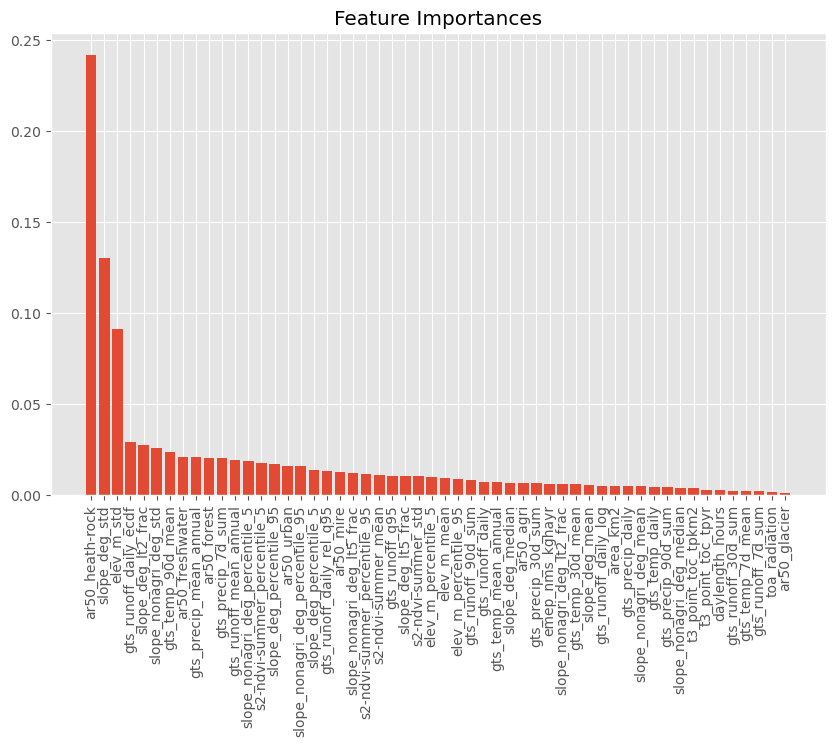

In [20]:
# Feature importances
fig_fpath = os.path.join(fig_folder, "feature_importance", f"feature_importance_xgboost_{feature_set}.png")

importances = best_pipeline.named_steps["regressor"].feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10, 6))
plt.title("Feature Importances")
plt.bar(range(X_train.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train.shape[1]), X_train.columns[indices], rotation=90)

plt.savefig(fig_fpath)

plt.show()

In [21]:
# import shap
# explainer = shap.TreeExplainer(xgb_model)
# shap_values = explainer.shap_values(X_sample)

## Prediction

Make daily predictions for randomly selected sites and compare them to the measured data.

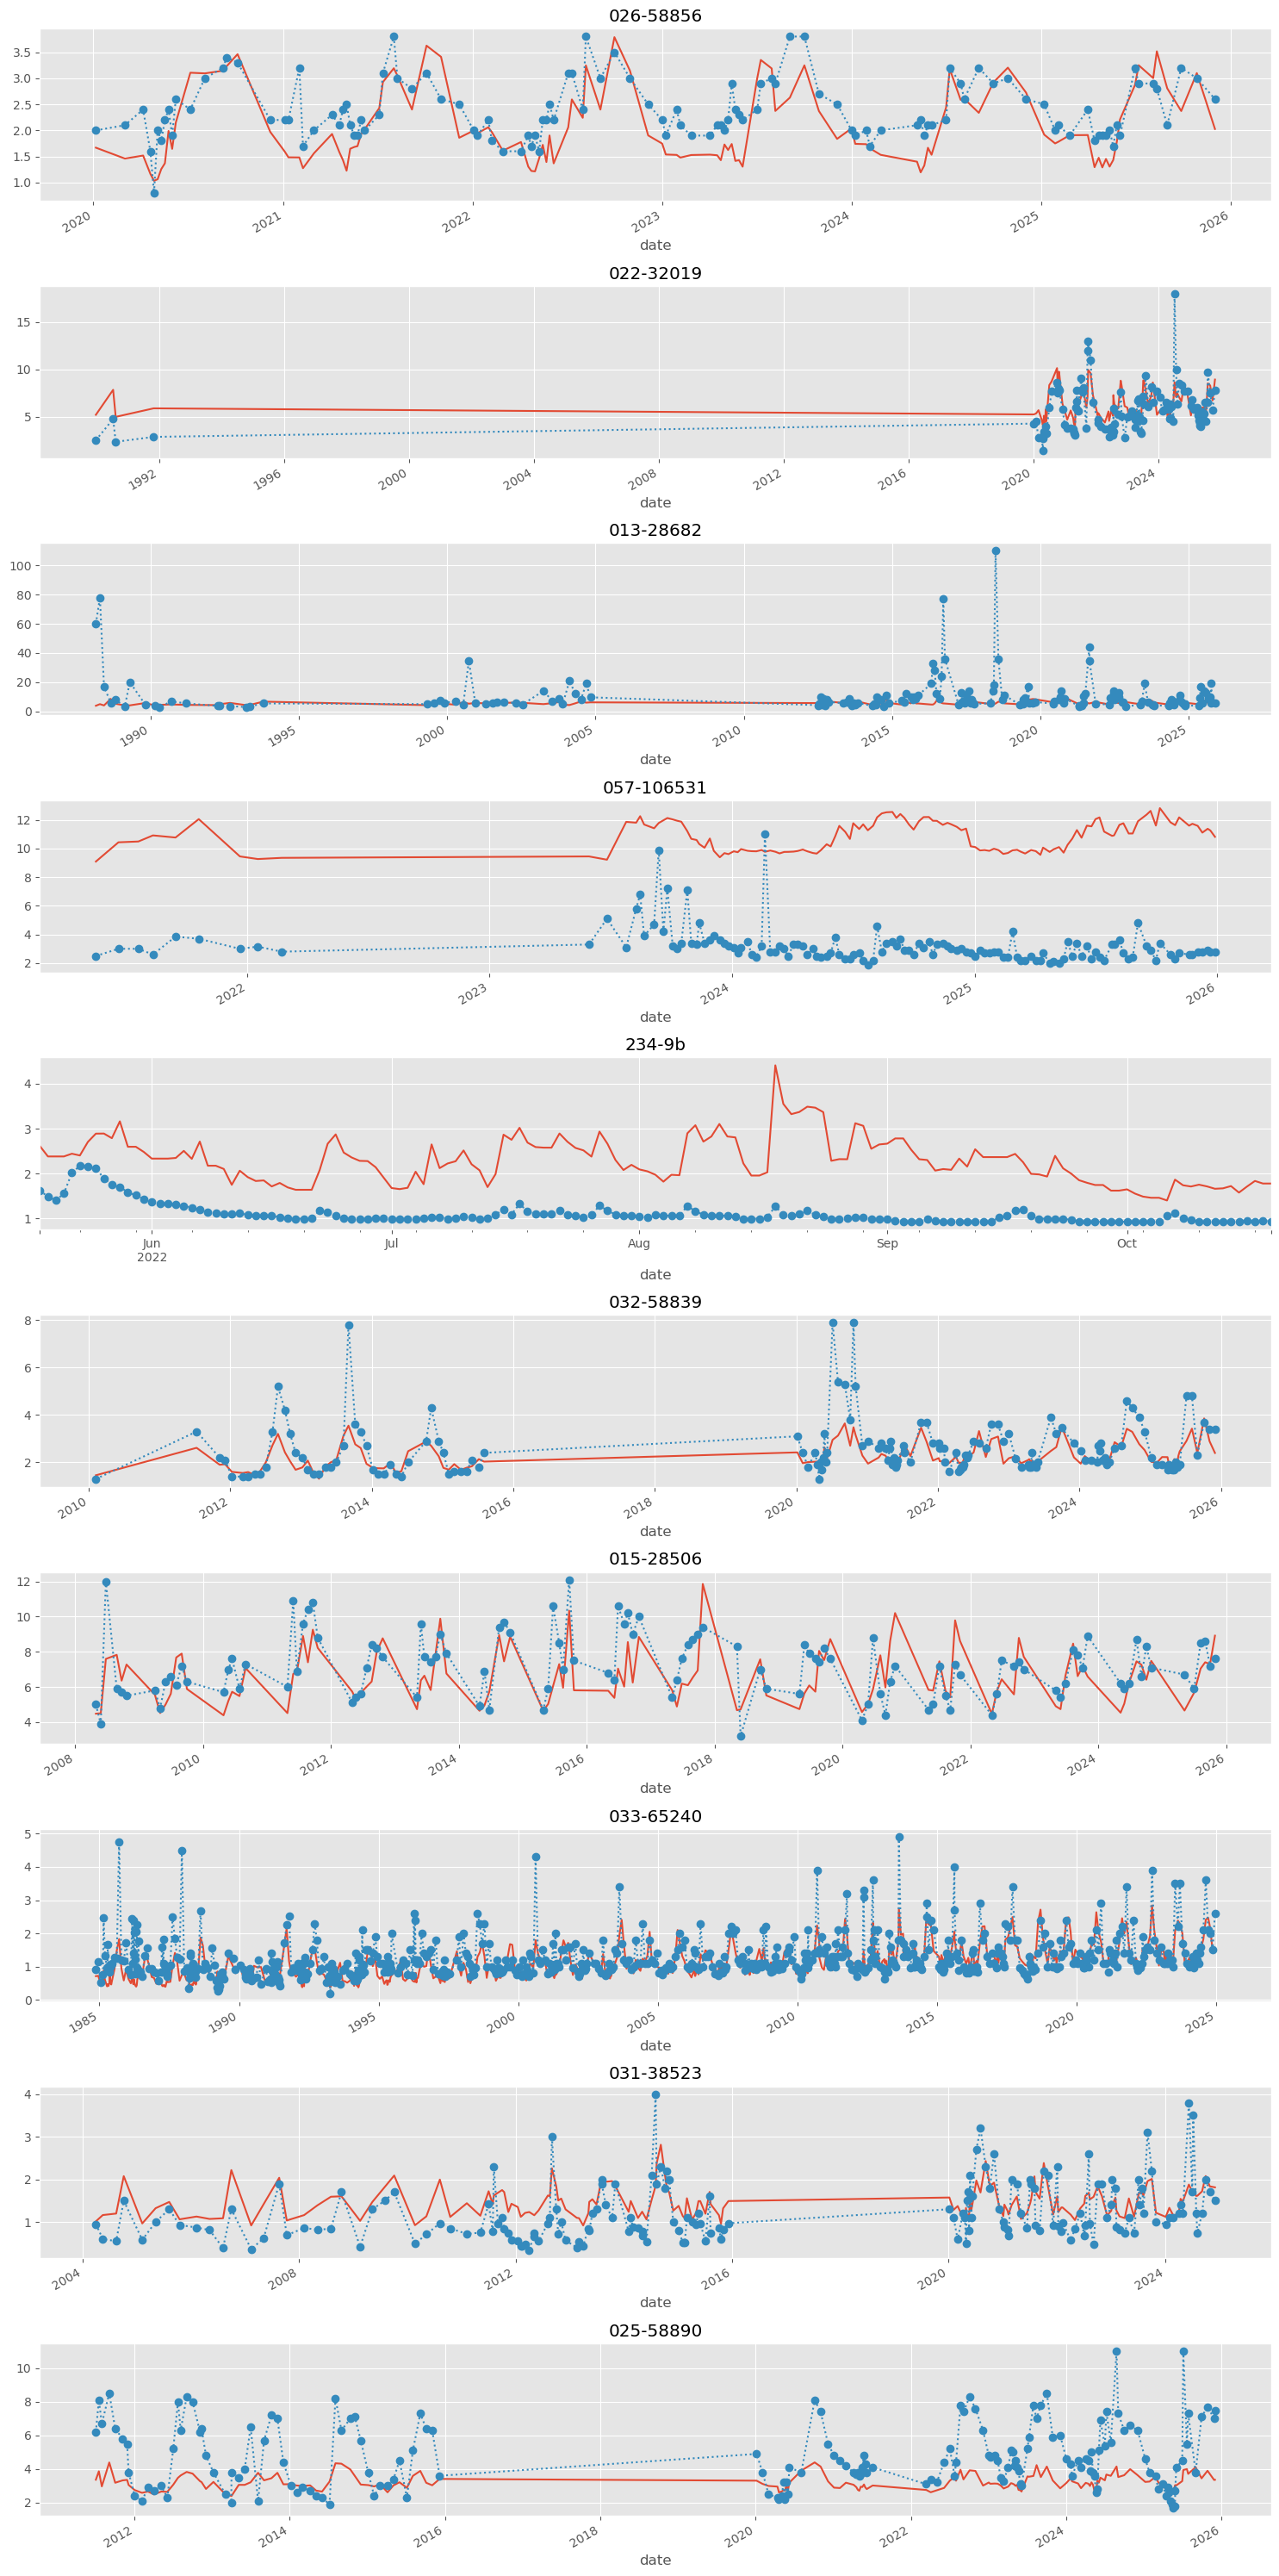

In [26]:
n_sites = 10  # Number of sites to plot
random_state = 42  # For reproducibility
min_obs = 100  # Only pick sites with n > min_obs
vassom_excl = [2, 12]  # Exclude Glomma and Drammenselva (high chance of a nearby site)

# Define pool of candidate sites
if cv_by_site:
    test_catches = list(test_groups.unique())
    candidate_df = df.query(f"{id_col} in @test_catches and vassomnr not in @vassom_excl")
else:
    candidate_df = df

# Find sites with enough observations
eligible_sites = (
    candidate_df
    .groupby(id_col)
    .size()
    .loc[lambda x: x >= min_obs]
    .index
)

# Sample sites
selected_sites = pd.Series(eligible_sites).sample(
    n=min(n_sites, len(eligible_sites)),
    random_state=random_state
)


# Plot
fig, axes = plt.subplots(
    n_sites,
    1,
    figsize=(15, 3*n_sites),
    sharex=False
)

if n_sites == 1:
    axes = [axes]

for ax, catch_id in zip(axes, selected_sites):

    catch_df = candidate_df.query(f"{id_col} == @catch_id").copy()

    pred_df = df.loc[df[id_col] == catch_id].copy()
    pred_df = pred_df.drop(columns=meta_cols + [y_var])

    pred_df = ml_utils.predict_target(
        pred_df,
        best_pipeline,
        y_var,
        X
    )

    date_s = df.loc[df[id_col] == catch_id, "date"]
    pred_df["date"] = date_s.values

    pred_df.set_index("date")[[f"pred_{y_var}"]].plot(
        ax=ax,
        ls="-",
        legend=False
    )

    catch_df.set_index("date")[[y_var]].plot(
        ax=ax,
        marker="o",
        ls=":",
        legend=False
    )

    ax.set_title(str(catch_id))

fig_fpath = os.path.join(fig_folder, "test-set_ts_predictions", f"ts_predictions_xgboost_{feature_set}.png")
plt.savefig(fig_fpath)

plt.tight_layout()
plt.show()

In [17]:
# # Predict with 95% prediction interval from bootstrapping
# pred_df = ml_utils.predict_with_interval(
#     pipeline, pred_df, y_var, X, alpha=0.95, n_boot=100
# )

# # Plot
# name = catch_df["station_name"].iloc[0]
# ax = pred_df.set_index("date")[[f"pred_{y_var}"]].plot(ls="-", figsize=(15, 6))
# catch_df.set_index("date")[[y_var]].plot(ax=ax, marker="o", ls=":")
# ax.fill_between(
#     pred_df["date"],
#     pred_df[f"lower_{y_var}"],
#     pred_df[f"upper_{y_var}"],
#     color="b",
#     alpha=0.1,
#     label="95% Prediction Interval",
# )
# ax.set_title(f"{name} ({catch_id})")
# plt.legend()